# 🧠 Aula 11 — Prática: Redes Neurais, Treinamento, Validação e Preparação para o Kaggle

**IIG0029 – Técnicas de IA I · Instituto de Inovação em Gestão (IIG) · UFG**

Este notebook é o **laboratório da Aula 11**. Ele percorre, do começo ao fim, o fluxo que você vai usar na avaliação prática da disciplina (projeto Kaggle):

> **Dados → Exploração (EDA) → Divisão treino/validação/teste → Padronização → Modelo *baseline* → Rede neural → Avaliação → Exportação → `submission.csv`**

### 🎯 O que você vai aprender
1. Explorar e entender um dataset antes de modelar (EDA).
2. Dividir os dados e padronizá-los **sem vazamento de dados** (*data leakage*).
3. Treinar um *baseline* e uma rede neural em Keras, e **comparar** os dois.
4. Ler **curvas de aprendizado** para diagnosticar subajuste e sobreajuste.
5. Avaliar com **matriz de confusão, precisão, recall e F1-Score** (e não só acurácia).
6. Aplicar o mesmo raciocínio a **imagens** (dígitos manuscritos).
7. **Salvar** o modelo e gerar um arquivo de submissão.

### 🗺️ Como este notebook se liga aos slides
| Parte do notebook | Seção dos slides |
|---|---|
| 1–2: Dados, divisão e padronização | Seção 2 — Engenharia de Dados |
| 3–6: Baseline, rede neural, curvas, fronteira de decisão | Seção 3 — Construção e Treinamento |
| 7–10: Avaliação, imagens, comparação, teste final | Seção 4 — Avaliação e Métricas |
| 11: Exportação e submissão | Seção 5 — Exportação e Kaggle |
| 12–13: Atividades e adaptação ao Kaggle | Atividade Supervisionada |

### ℹ️ Sobre o dataset desta prática
Nos slides, o exemplo-fio-condutor é o **Titanic** (um arquivo `train.csv` do Kaggle). **Aqui**, para que o notebook rode em qualquer lugar **sem baixar nada**, usamos o dataset **Breast Cancer Wisconsin (Diagnostic)**, que já vem dentro do Scikit-Learn. O fluxo de trabalho é exatamente o mesmo; na Parte 13 mostramos como trocar por um CSV do Kaggle.

> ⚠️ **Aviso:** o dataset de câncer é usado **apenas para fins didáticos**. Nada aqui serve para diagnóstico real.

### 🧭 Legenda
🔹 conceito-chave · ⚠️ atenção · ➕ **Extra** (célula adicionada para ajudar a entender; não estava no script original) · ✏️ exercício

### ▶️ Como executar
Use **Ambiente de execução → Executar tudo** (Colab) ou rode célula por célula, **em ordem**. O notebook leva de 2 a 3 minutos e **não precisa de GPU**. Os números exatos podem variar um pouco entre execuções e versões das bibliotecas.

---
## 🔧 Parte 0 — Preparando o ambiente

Primeiro, importamos as bibliotecas. Cada grupo tem um papel:

| Biblioteca | Para que serve neste notebook |
|---|---|
| `numpy`, `pandas` | Arrays numéricos e tabelas (DataFrames) |
| `matplotlib`, `seaborn` | Gráficos |
| `sklearn.datasets` | Datasets prontos (`load_breast_cancer`, `load_digits`) |
| `sklearn.model_selection` | `train_test_split`: divide os dados |
| `sklearn.preprocessing` | `StandardScaler`: padroniza os atributos |
| `sklearn.linear_model` | `LogisticRegression`: nosso modelo *baseline* |
| `sklearn.metrics` | Acurácia, precisão, recall, F1, matriz de confusão |
| `sklearn.decomposition` | `PCA`: reduz dimensões para desenhar gráficos 2D |
| `tensorflow` / `keras` | Redes neurais (`Sequential`, `Dense`, `Dropout`, `EarlyStopping`) |

💡 A linha `warnings.filterwarnings('ignore')` **esconde avisos** para deixar a saída limpa em sala de aula. Ao programar seus projetos, **remova-a** para não perder avisos importantes.

In [1]:
import warnings
warnings.filterwarnings('ignore')   # esconde avisos (remova ao depurar seus projetos)

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # reduz as mensagens internas do TensorFlow (definir ANTES de importar o tf)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA

import tensorflow as tf
tf.get_logger().setLevel('ERROR')            # silencia avisos repetitivos do TensorFlow
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Estilo visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print(f'✅ TensorFlow: {tf.__version__} | NumPy: {np.__version__} | Pandas: {pd.__version__}')

I0000 00:00:1792534543.965869    1004 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792534545.134219    1004 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


✅ TensorFlow: 2.21.0 | NumPy: 2.4.4 | Pandas: 3.0.2


**Como ler a saída:** a linha com ✅ confirma as versões instaladas. Se alguma biblioteca faltar, você verá um `ModuleNotFoundError` — nesse caso, instale-a (no Colab: `!pip install nome-da-biblioteca`) e execute a célula de novo.

ℹ️ Se aparecer uma mensagem começando com `I0000 ... oneDNN custom operations are on`, **não é erro**: é um aviso informativo do TensorFlow (explica que cálculos em ponto flutuante podem variar minimamente entre execuções). Pode ignorá-lo.

---
## 📊 Parte 1 — Conhecendo os dados (EDA)

> 🔹 **Regra de ouro:** antes de criar qualquer modelo, *converse com os dados*. Nenhum modelo, por mais sofisticado, conserta dados mal compreendidos.

### O dataset: Breast Cancer Wisconsin (Diagnostic)
- **569 pacientes**, cada uma com **30 atributos numéricos**.
- Os atributos foram calculados a partir de imagens digitalizadas de uma punção aspirativa por agulha fina (PAAF) de massas mamárias, e descrevem os **núcleos das células** (raio, textura, perímetro, área, suavidade, etc.). São **10 medidas** × **3 estatísticas** (média, erro padrão e "pior" valor) = 30 colunas [1].
- O **alvo** (`target`) é o diagnóstico:

| `target` | Significado |
|---|---|
| **0** | Maligno (*malignant*) |
| **1** | Benigno (*benign*) |

> ⚠️ **Cuidado com a convenção:** no Scikit-Learn, **1 = benigno**. Em métricas como precisão e recall, a "classe positiva" é a **1** — ou seja, aqui **"positivo" significa "benigno"**. Guarde isso: vamos precisar na Parte 7.

In [2]:
# Carrega o dataset que já vem embutido no Scikit-Learn (nenhum download necessário)
data = load_breast_cancer()

# Monta uma tabela (DataFrame): colunas = atributos; acrescenta a coluna 'target' (diagnóstico)
df_raw = pd.DataFrame(data.data, columns=data.feature_names)
df_raw['target'] = data.target

print(f'📊 Formato do Dataset: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas')
display(df_raw.head())   # mostra as 5 primeiras linhas

📊 Formato do Dataset: 569 linhas x 31 colunas


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Como ler a saída:** `569 linhas x 31 colunas` = 569 pacientes × (30 atributos + 1 alvo). O Pandas mostra `...` para abreviar colunas do meio, mas todas existem.

### ➕ Extra: há valores nulos? As escalas são parecidas?
Duas perguntas rápidas da EDA, que justificam etapas futuras:
1. **Existem valores ausentes?** (se sim, precisaríamos de imputação, como vimos nos slides).
2. **Os atributos estão na mesma escala?** (se não, precisaremos padronizá-los).

In [3]:
# ➕ EXTRA: verificações rápidas de EDA
print('Total de valores nulos no dataset:', int(df_raw.isna().sum().sum()))

# Compare o menor e o maior valor de três atributos de escalas muito diferentes
display(df_raw[['mean radius', 'mean area', 'mean smoothness']].describe().loc[['min', 'max']])

Total de valores nulos no dataset: 0


,mean radius,mean area,mean smoothness
min,6.981,143.5,0.05263
max,28.110,2501.0,0.16340


**Interpretação:**
- **Nulos = 0**: este dataset já vem completo (no Titanic dos slides, a coluna `Age` tem nulos e precisa de `SimpleImputer`).
- **Escalas**: `mean area` vai de centenas a milhares, enquanto `mean smoothness` fica entre ~0,05 e ~0,16. Sem padronização, atributos de escala grande **dominariam** o treino da rede. É exatamente isso que o `StandardScaler` resolverá na Parte 2.

### Quantas amostras há de cada classe?
Verificar o **balanceamento** das classes é essencial: se uma classe for muito rara, a acurácia pode enganar (lembra do paradoxo do diagnóstico raro nos slides?).

> 🔧 **Correção em relação ao script original:** o método `value_counts()` ordena por frequência (benigno, com 357, vem primeiro), mas os rótulos do gráfico eram escritos na ordem `[maligno, benigno]`, o que **trocava as barras**. Usamos `.sort_index()` para alinhar a contagem à ordem `0 = maligno, 1 = benigno`.

📈 Distribuição da Classe Alvo:
  • Classe 0 (malignant): 212 amostras (37.26%)
  • Classe 1 (benign): 357 amostras (62.74%)


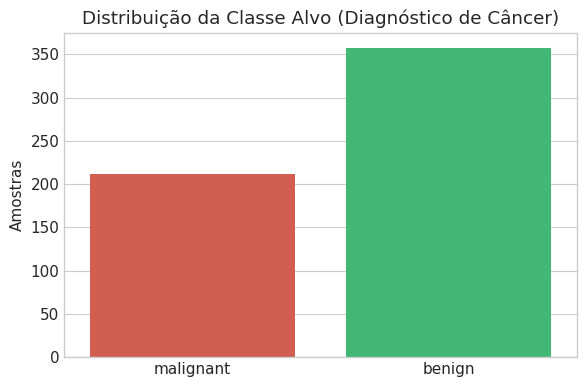

✅ Gráfico de distribuição gerado!


In [4]:
# Conta as amostras por classe. sort_index() garante a ordem 0 (maligno), 1 (benigno)
target_counts = df_raw['target'].value_counts().sort_index()
print('📈 Distribuição da Classe Alvo:')
for k, v in target_counts.items():
    pct = (v / len(df_raw)) * 100
    print(f'  • Classe {k} ({data.target_names[k]}): {v} amostras ({pct:.2f}%)')

plt.figure(figsize=(6, 4))
nomes = [data.target_names[0], data.target_names[1]]
ax = sns.barplot(x=nomes, y=target_counts.values, hue=nomes, palette=['#e74c3c', '#2ecc71'], legend=False)
plt.title('Distribuição da Classe Alvo (Diagnóstico de Câncer)')
plt.ylabel('Amostras')
plt.tight_layout()
plt.show()   # (o script original usava plt.close(), que impede o gráfico de aparecer no notebook)
print('✅ Gráfico de distribuição gerado!')

**Interpretação:** cerca de **63% benignos** e **37% malignos**: um desbalanceamento **leve**. Um "modelo preguiçoso" que respondesse *sempre benigno* teria ~**62,7%** de acurácia sem aprender nada: esse é o piso que qualquer modelo útil precisa superar.

---
## ✂️ Parte 2 — Divisão dos dados e padronização (sem vazamento!)

### 🔹 Por que três conjuntos?
| Conjunto | Para quê | Quanto |
|---|---|---|
| **Treino** | A rede **aprende** (ajusta os pesos) | 60% |
| **Validação** | Escolhemos o modelo e **paramos o treino** (EarlyStopping) | 20% |
| **Teste** | Nota **final e honesta**, usada uma única vez | 20% |

Fazemos **duas divisões**: primeiro separamos 20% para teste; dos 80% restantes, separamos 25% para validação (0,80 × 0,25 = 0,20).

- `stratify=y` mantém a **mesma proporção de classes** em todos os conjuntos.
- `random_state=42` torna a divisão **reprodutível** (qualquer pessoa obtém as mesmas linhas).

### 🔹 O que é *data leakage* (vazamento de dados)?
O `StandardScaler` calcula **média e desvio-padrão**. Se ele "olhasse" os dados de validação/teste, informações do futuro **vazariam** para o treino, como estudar com a prova na mão. Por isso:

> **`fit` (aprender média e desvio) → só no treino · `transform` (aplicar) → treino, validação e teste.**

In [5]:
# X = atributos (matriz 569 x 30); y = alvo (vetor de 0 e 1)
X = df_raw.drop(columns=['target']).values
y = df_raw['target'].values

# 1ª divisão: separa 20% para TESTE (guardado e só usado no final)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

# 2ª divisão: dos 80% restantes, separa 25% para VALIDAÇÃO (= 20% do total)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full)

# Padronização Z-score: x_padronizado = (x - média) / desvio_padrão
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit SÓ no treino (aprende média e desvio) + transforma
X_val_scaled = scaler.transform(X_val)           # apenas transform: usa a média/desvio do TREINO
X_test_scaled = scaler.transform(X_test)         # apenas transform: idem

print(f'✂️ Divisão: Treino={X_train.shape[0]} | Validação={X_val.shape[0]} | Teste={X_test.shape[0]}')
print('✅ Padronização Z-score concluída sem vazamento de dados!')

✂️ Divisão: Treino=341 | Validação=114 | Teste=114
✅ Padronização Z-score concluída sem vazamento de dados!


**Como ler a saída:** `341 / 114 / 114` = 60% / 20% / 20% de 569 amostras. Após a padronização, cada atributo do treino fica com média ≈ 0 e desvio ≈ 1.

### ➕ Extra: o `stratify` realmente manteve as proporções?
Confira a fração de cada classe nos três conjuntos (deve ficar ≈ 37% de malignos em todos):

In [6]:
# ➕ EXTRA: proporção de cada classe em cada conjunto (efeito do stratify=y)
for nome, yy in [('Treino', y_train), ('Validação', y_val), ('Teste', y_test)]:
    print(f'{nome:<10} -> malignos: {np.mean(yy == 0) * 100:5.1f}% | benignos: {np.mean(yy == 1) * 100:5.1f}%  (n={len(yy)})')

Treino     -> malignos:  37.2% | benignos:  62.8%  (n=341)
Validação  -> malignos:  37.7% | benignos:  62.3%  (n=114)
Teste      -> malignos:  36.8% | benignos:  63.2%  (n=114)


---
## 📌 Parte 3 — O modelo *baseline* (a régua de comparação)

### 🔹 Por que começar com um modelo simples?
Um **baseline** é um modelo simples e rápido que serve de **referência**. Se uma rede neural complexa não superar o baseline, ela **não vale o custo extra**. A **Regressão Logística** é o baseline clássico para classificação binária: ela traça uma fronteira **linear** entre as classes.

Vamos medir quatro métricas na **validação** (lembrando: positivo = benigno):

| Métrica | Pergunta que responde |
|---|---|
| **Acurácia** | Qual a fração total de acertos? |
| **Precisão** | Das vezes que previu "benigno", quantas acertou? |
| **Recall** | De todos os benignos reais, quantos encontrou? |
| **F1-Score** | Equilíbrio (média harmônica) entre precisão e recall |

In [7]:
# Cria e treina a Regressão Logística com os dados padronizados do TREINO
baseline = LogisticRegression(random_state=42)
baseline.fit(X_train_scaled, y_train)

# Faz previsões na VALIDAÇÃO (dados que o modelo nunca viu no treino)
y_pred_base = baseline.predict(X_val_scaled)

# Calcula as métricas comparando previsões (y_pred_base) com a verdade (y_val)
acc_base = accuracy_score(y_val, y_pred_base)
prec_base = precision_score(y_val, y_pred_base)
rec_base = recall_score(y_val, y_pred_base)
f1_base = f1_score(y_val, y_pred_base)

print(f'📌 Baseline (Regressão Logística) -> Acurácia: {acc_base*100:.2f}% | F1-Score: {f1_base*100:.2f}%')

📌 Baseline (Regressão Logística) -> Acurácia: 99.12% | F1-Score: 99.30%


**Interpretação:** o baseline já é **muito forte** (acima de 99%). Isso é um indício importante: este dataset é **quase linearmente separável**, ou seja, uma linha (hiperplano) já separa bem as classes. Guarde essa pista para quando compararmos com a rede neural: **mais complexidade nem sempre traz mais desempenho**.

⚠️ A validação tem só 114 amostras: **1 erro a mais ou a menos muda a acurácia em ~0,9 ponto percentual** (1/114). Diferenças pequenas entre modelos podem ser apenas ruído.

---
## 🧱 Parte 4 — Construindo e treinando a Rede Neural (Keras)

### Arquitetura
```
 Entrada (30 atributos)
      │
 Dense(32, ReLU)      ← 1ª camada oculta: 32 neurônios
      │
 Dropout(0.3)         ← desliga 30% dos neurônios (só no treino)
      │
 Dense(16, ReLU)      ← 2ª camada oculta: 16 neurônios
      │
 Dropout(0.2)         ← desliga 20% dos neurônios (só no treino)
      │
 Dense(1, sigmoid)    ← saída: probabilidade de ser benigno (0 a 1)
```

| Componente | O que faz |
|---|---|
| `Input(shape=(30,))` | Declara que cada amostra tem 30 números |
| `Dense(32, activation='relu')` | Camada totalmente conectada; **ReLU** zera valores negativos (introduz não-linearidade) |
| `Dropout(0.3)` | **Regularização:** a cada passo, "desliga" 30% dos neurônios ao acaso, forçando a rede a não depender de poucos caminhos (combate o *overfitting*) |
| `Dense(1, activation='sigmoid')` | **Sigmoide** espreme a saída para o intervalo (0, 1) → leitura como **probabilidade** |

### Compilação (`compile`)
- **`loss='binary_crossentropy'`**: função de perda para classificação **binária** (combina com a saída sigmoide).
- **`optimizer=Adam(learning_rate=0.005)`**: o Adam ajusta os pesos; a **taxa de aprendizado** é o tamanho do passo. Aqui usamos 0,005 (5× o padrão, 0,001), pois com poucos dados queremos aprender mais rápido. *(Nos slides o exemplo usa o padrão; ambos funcionam — experimente!)*
- **`metrics=['accuracy']`**: o que acompanhar durante o treino.

### Treinamento (`fit`) e **EarlyStopping**
- `epochs=100`: teto de passagens completas pelos dados de treino. `batch_size=16`: a rede atualiza os pesos a cada 16 amostras.
- **`EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)`**: monitora a perda de **validação**; se ela **não melhorar por 15 épocas seguidas**, o treino **para sozinho** e os pesos voltam aos da **melhor época**.
  > ⚠️ O EarlyStopping **precisa** de dados de validação (`validation_data`); sem eles não há o que monitorar.

In [8]:
tf.random.set_seed(42)   # fixa a aleatoriedade do TensorFlow (resultados mais reprodutíveis)

# 1) DEFINIR a rede: camadas empilhadas em sequência
nn_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),        # 30 atributos de entrada
    Dense(32, activation='relu', name='Oculta_1'),
    Dropout(0.3, name='Dropout_1'),
    Dense(16, activation='relu', name='Oculta_2'),
    Dropout(0.2, name='Dropout_2'),
    Dense(1, activation='sigmoid', name='Saida')    # probabilidade de ser benigno
], name='Rede_Neural_Kaggle')

# 2) COMPILAR: otimizador + função de perda + métrica
nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
                 loss='binary_crossentropy', metrics=['accuracy'])
nn_model.summary()   # tabela de camadas e número de parâmetros

# 3) Callback de parada precoce
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0)

# 4) TREINAR (o histórico fica guardado em 'history')
history = nn_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),   # dados que o EarlyStopping monitora
    epochs=100, batch_size=16,
    callbacks=[early_stop], verbose=0         # verbose=0: não imprime cada época
)
print('✅ Treinamento da Rede Neural Keras concluído!')

Model: "Rede_Neural_Kaggle"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Oculta_1 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Oculta_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Saida (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

✅ Treinamento da Rede Neural Keras concluído!


**Como ler o `summary()`:** cada linha é uma camada; `Param #` é quantos números a camada precisa aprender.
- `Oculta_1`: 30 × 32 pesos + 32 vieses = **992**
- `Oculta_2`: 32 × 16 + 16 = **528**
- `Saida`: 16 × 1 + 1 = **17**
- Os `Dropout` não têm parâmetros. **Total: 1.537.**

💡 Repare: a rede tem **1.537 parâmetros** para apenas **341 amostras de treino**: mais "botões" do que exemplos! Por isso a regularização (Dropout, EarlyStopping) é tão importante aqui.

⚠️ **Variação entre execuções:** mesmo fixando a semente, redes neurais podem dar resultados **ligeiramente diferentes** entre máquinas e versões (cálculos paralelos em ponto flutuante). Já o *baseline* (Regressão Logística) é determinístico. Por isso as interpretações abaixo se baseiam nas **saídas desta execução**.

### ➕ Extra: em que época o treino parou?
O `EarlyStopping` interrompe quando a validação para de melhorar. Quantas épocas rodaram, e qual foi a melhor?

In [9]:
# ➕ EXTRA: descobrir a época de parada e a melhor época
epocas_rodadas = len(history.history['loss'])
melhor_epoca = int(np.argmin(history.history['val_loss'])) + 1
print(f'Épocas executadas: {epocas_rodadas} (teto: 100)')
print(f'Melhor época (menor val_loss): {melhor_epoca}')
print(f'Diferença = {epocas_rodadas - melhor_epoca} épocas (≈ patience = 15, esperando uma melhora que não veio)')

Épocas executadas: 21 (teto: 100)
Melhor época (menor val_loss): 6
Diferença = 15 épocas (≈ patience = 15, esperando uma melhora que não veio)


**Interpretação:** o treino parou antes das 100 épocas, **exatamente `patience` épocas depois** da melhor. Com `restore_best_weights=True`, o modelo final usa os pesos da **melhor época**, e não os da última. (Este valor é o ponto de partida da ✏️ Atividade 2.)

---
## 📈 Parte 5 — Curvas de aprendizado

As curvas mostram **como o treino evoluiu época a época**, para **treino** (linha cheia) e **validação** (tracejada).

### 🔹 Como diagnosticar
| O que você vê | Diagnóstico | O que fazer |
|---|---|---|
| Treino **e** validação com erro alto | **Subajuste** (*underfitting*) | Mais neurônios/camadas/épocas |
| Treino cai, **validação sobe** | **Sobreajuste** (*overfitting*): o modelo *decorou* o treino | Dropout, EarlyStopping, rede menor |
| As duas caem e **ficam próximas** | **Bom ajuste** | 👍 |

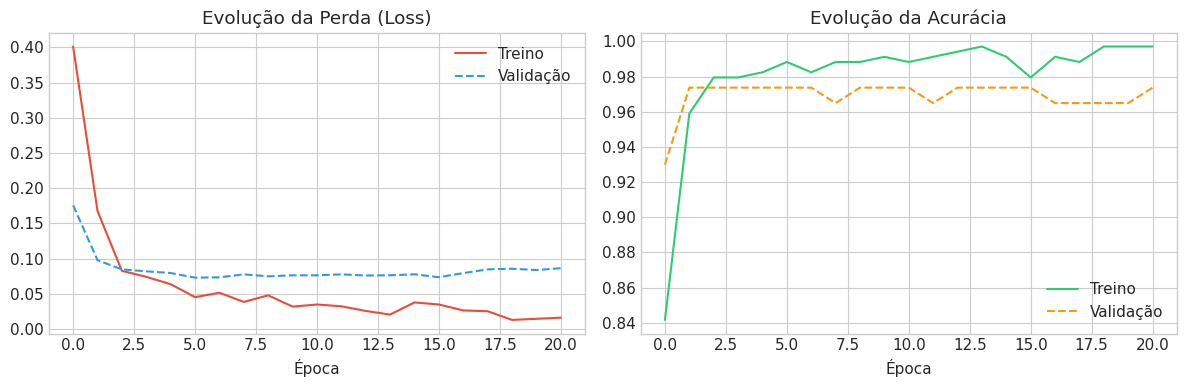

✅ Curvas de aprendizado geradas!


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Esquerda: PERDA (loss) — quanto MENOR, melhor
ax1.plot(history.history['loss'], label='Treino', color='#e74c3c')
ax1.plot(history.history['val_loss'], label='Validação', color='#3498db', linestyle='--')
ax1.set_title('Evolução da Perda (Loss)')
ax1.set_xlabel('Época')
ax1.legend()

# Direita: ACURÁCIA — quanto MAIOR, melhor
ax2.plot(history.history['accuracy'], label='Treino', color='#2ecc71')
ax2.plot(history.history['val_accuracy'], label='Validação', color='#f39c12', linestyle='--')
ax2.set_title('Evolução da Acurácia')
ax2.set_xlabel('Época')
ax2.legend()

plt.tight_layout()
plt.show()
print('✅ Curvas de aprendizado geradas!')

**Interpretação (nesta execução):** o treino rodou **21 épocas**, mas a **melhor foi a 6**. Depois dela, a perda de **treino continuou caindo** enquanto a de **validação estacionou ou subiu levemente**: é o sinal clássico do **início do sobreajuste** (a rede começa a decorar o treino). Foi exatamente isso que o **EarlyStopping** detectou: ele esperou `patience` épocas, parou e **devolveu os pesos da época 6**.

💡 É comum a curva de **treino começar acima** da validação: o Dropout está ligado só no treino, e a perda de treino é uma média calculada durante a época, enquanto o modelo ainda está melhorando.

---
## 🗺️ Parte 6 — Visualizando uma fronteira de decisão (projeção PCA 2D)

Nossos dados têm **30 dimensões**: impossível desenhar. O **PCA** (*Principal Component Analysis*) resolve isso: ele **projeta** os dados em apenas **2 eixos** (os "componentes principais") que preservam o máximo possível da variação original.

Depois, treinamos uma **pequena rede nova só para esses 2 eixos**, e pintamos o plano com a decisão da rede em cada ponto (🔴 maligno · 🟢 benigno).

> ⚠️ **Atenção:** este modelo (`model_2d`) é **diferente** do `nn_model` (que usa as 30 dimensões). Ele existe **apenas para visualização**: serve para **enxergar** que uma rede com ReLU consegue desenhar fronteiras **curvas** (não lineares), enquanto a regressão logística só desenha retas.

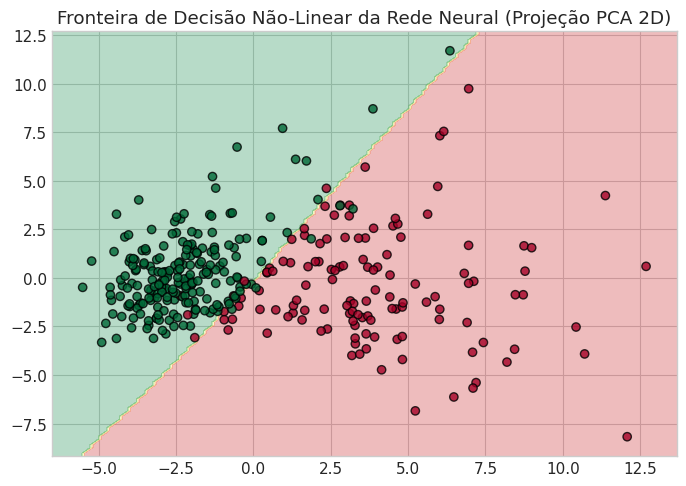

✅ Gráfico de fronteiras de decisão 2D gerado!


In [11]:
# Reduz de 30 para 2 dimensões (aprendendo o PCA só no treino, como no scaler)
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

# Rede pequena treinada nos 2 componentes (apenas para visualizar)
model_2d = Sequential([Input(shape=(2,)), Dense(16, activation='relu'), Dense(8, activation='relu'), Dense(1, activation='sigmoid')])
model_2d.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_2d.fit(X_train_pca, y_train, epochs=50, batch_size=16, verbose=0)

# Cria uma GRADE de pontos cobrindo o plano e pede a previsão da rede em cada ponto
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))

Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0)
Z = (Z > 0.5).astype(int).reshape(xx.shape)   # probabilidade > 0,5  →  classe 1

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlGn')   # regiões de decisão
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='RdYlGn', edgecolors='k', alpha=0.8)  # pacientes
plt.title('Fronteira de Decisão Não-Linear da Rede Neural (Projeção PCA 2D)')
plt.tight_layout()
plt.show()
print('✅ Gráfico de fronteiras de decisão 2D gerado!')

**Como ler o gráfico:** cada ponto é um paciente do treino; o **fundo colorido** mostra a decisão da rede naquela região. A fronteira entre as cores é a **fronteira de decisão**.

🔎 **Observe a forma da fronteira.** Uma rede com ReLU *pode* desenhar curvas, mas **só curva quando os dados pedem**. Neste dataset as classes são **quase linearmente separáveis** (lembra do baseline acima de 99%?), então é comum a fronteira sair **quase reta**. Compare com as "luas" dos slides, onde a reta falha e a rede precisa curvar.

### ➕ Extra: quanta informação o PCA 2D preservou?

In [12]:
# ➕ EXTRA: fração da variação original que os 2 componentes principais explicam
print('Variância explicada por componente:', np.round(pca.explained_variance_ratio_, 3))
print(f'Total preservado nos 2 eixos: {pca.explained_variance_ratio_.sum() * 100:.1f}%')

Variância explicada por componente: [0.442 0.196]
Total preservado nos 2 eixos: 63.8%


**Interpretação:** os 2 eixos guardam **uma parte** (não a totalidade) da informação dos 30 atributos. Por isso o gráfico é uma **ilustração**, e a separação real das classes (nas 30 dimensões) é melhor do que parece aqui.

---
## 🧪 Parte 7 — Avaliação: relatório e matriz de confusão

### 🔹 A matriz de confusão
Ela cruza o que o modelo **previu** com a **realidade**. Lembrando: aqui **positivo = benigno (1)**.

|  | **Previu Maligno (0)** | **Previu Benigno (1)** |
|---|---|---|
| **Real: Maligno (0)** | ✅ VN: acertou | ❌ **FP**: *disse benigno, mas era maligno* |
| **Real: Benigno (1)** | ❌ FN: *disse maligno, mas era benigno* | ✅ VP: acertou |

### 🔹 Qual erro é pior?
Em triagem de câncer, **o erro mais grave é classificar um tumor maligno como benigno** (o **FP** desta tabela, por causa da convenção "positivo = benigno"). O **relatório** (`classification_report`) mostra precisão, recall e F1 **de cada classe**, o que permite olhar a classe maligna separadamente.

📋 Relatório de Desempenho (Keras MLP):


              precision    recall  f1-score   support

     Maligno       0.95      0.98      0.97        43
     Benigno       0.99      0.97      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Matriz de confusão (linhas = real, colunas = previsto):
 [[42  1]
 [ 2 69]]


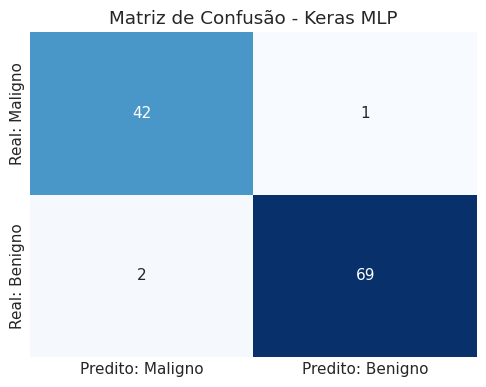

✅ Matriz de confusão gerada!


In [13]:
# Probabilidades da rede na VALIDAÇÃO → converte em classes com limiar 0,5
y_pred_probs = nn_model.predict(X_val_scaled, verbose=0)
y_pred_nn = (y_pred_probs > 0.5).astype(int).flatten()

acc_nn = accuracy_score(y_val, y_pred_nn)
prec_nn = precision_score(y_val, y_pred_nn)
rec_nn = recall_score(y_val, y_pred_nn)
f1_nn = f1_score(y_val, y_pred_nn)

print('📋 Relatório de Desempenho (Keras MLP):')
print(classification_report(y_val, y_pred_nn, target_names=['Maligno', 'Benigno']))

# Matriz de confusão: linhas = realidade, colunas = previsão
cm = confusion_matrix(y_val, y_pred_nn)
print('Matriz de confusão (linhas = real, colunas = previsto):\n', cm)   # ➕ extra: valores numéricos

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predito: Maligno', 'Predito: Benigno'],
            yticklabels=['Real: Maligno', 'Real: Benigno'])
plt.title('Matriz de Confusão - Keras MLP')
plt.tight_layout()
plt.show()
print('✅ Matriz de confusão gerada!')

**Interpretação (nesta execução; seus números podem variar um pouco):**

| | Previu Maligno | Previu Benigno |
|---|---|---|
| **Real: Maligno** | VN = **42** | FP = **1** |
| **Real: Benigno** | FN = **2** | VP = **69** |

- **Acertos:** 111 de 114 (diagonal principal).
- **1** tumor(es) **maligno(s) classificado(s) como benigno(s)**: é o erro **mais grave** em triagem, pois pode atrasar um tratamento.
- **2** tumor(es) **benigno(s) classificado(s) como maligno(s)**: um falso alarme, que costuma levar a exames adicionais.

💡 Note como a **acurácia sozinha esconde essa diferença**: os dois tipos de erro contam igual na acurácia, mas têm **custos** muito diferentes. É por isso que olhamos precisão, recall e a matriz.

---
## 🖼️ Parte 8 — Visão computacional: reconhecendo dígitos manuscritos

O mesmo raciocínio vale para **imagens**. O dataset `Digits` tem **1.797 imagens 8×8** (64 pixels em tons de cinza) de dígitos de 0 a 9 [2].

### 🔹 Como uma rede "enxerga" uma imagem
Para o computador, uma imagem é uma **matriz de números** (brilho de cada pixel, de 0 a 16). Cada imagem vira um **vetor de 64 entradas**. (No Scikit-Learn, `digits.data` já vem "achatado" em 64 colunas.)

### Diferenças em relação ao modelo de câncer
| | Câncer (binário) | Dígitos (multiclasse) |
|---|---|---|
| Classes | 2 | **10** |
| Saída | 1 neurônio, **sigmoid** | 10 neurônios, **softmax** (uma probabilidade por dígito; somam 1) |
| Perda | `binary_crossentropy` | **`sparse_categorical_crossentropy`** (rótulos inteiros 0–9) |
| F1 | binário | **`average='weighted'`** (média ponderada pelo nº de amostras de cada classe) |

- **Normalização:** dividimos por **16** para levar os pixels a [0, 1] (o brilho máximo no `Digits` é 16).

### ➕ Extra: vamos *ver* os dados antes de modelar

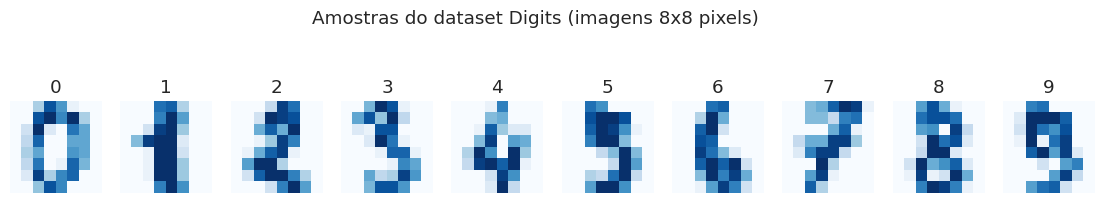

In [14]:
# ➕ EXTRA: visualizar 10 imagens do dataset (um exemplo de cada dígito)
digits = load_digits()

fig, axes = plt.subplots(1, 10, figsize=(14, 2.2))
for dig, ax in enumerate(axes):
    idx = np.where(digits.target == dig)[0][0]          # primeira imagem do dígito 'dig'
    ax.imshow(digits.images[idx], cmap='Blues')
    ax.set_title(str(dig))
    ax.axis('off')
plt.suptitle('Amostras do dataset Digits (imagens 8x8 pixels)', y=1.12)
plt.show()

In [15]:
# Atributos: 64 pixels por imagem, normalizados para [0, 1] (dividindo pelo brilho máximo, 16)
digits = load_digits()
X_img = digits.data / 16.0
y_img = digits.target

X_tr_img, X_te_img, y_tr_img, y_te_img = train_test_split(
    X_img, y_img, test_size=0.25, random_state=42, stratify=y_img)

tf.random.set_seed(42)   # ➕ adicionado: resultado mais reprodutível

vision_model = Sequential([
    Input(shape=(64,)),                       # 64 pixels de entrada
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')           # 10 classes (dígitos 0 a 9)
])

vision_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
vision_model.fit(X_tr_img, y_tr_img, epochs=40, batch_size=32, verbose=0)

# A saída tem 10 probabilidades por imagem; argmax escolhe a de maior valor
y_pred_img = np.argmax(vision_model.predict(X_te_img, verbose=0), axis=1)

acc_img = accuracy_score(y_te_img, y_pred_img)
f1_img = f1_score(y_te_img, y_pred_img, average='weighted')

print(f'🎯 Visão Computacional (Digits) -> Acurácia: {acc_img*100:.2f}% | F1-Score: {f1_img*100:.2f}%')

🎯 Visão Computacional (Digits) -> Acurácia: 97.78% | F1-Score: 97.78%


**Interpretação:** uma rede **bem pequena**, treinada em segundos, reconhece dígitos com acurácia por volta de **98–99%**. Note que aqui o conjunto de teste (`X_te_img`) é usado para avaliar *uma vez*; no projeto do Kaggle, esse papel é do `test.csv` oculto.

---
## 📋 Parte 9 — Comparando os modelos

Reunimos os resultados em uma única tabela. É assim que você deve **justificar a escolha do modelo** no seu projeto final.

In [16]:
df_comparativo = pd.DataFrame({
    'Modelo / Algoritmo': ['Baseline (Regressão Logística)', 'Rede Neural Densa (Keras MLP)', 'Rede Neural de Visão (Keras)'],
    'Tipo de Dados': ['Tabular (Cancer Diagnostic)', 'Tabular (Cancer Diagnostic)', 'Imagens (Digits 8x8)'],
    'Acurácia (%)': [f'{acc_base*100:.2f}%', f'{acc_nn*100:.2f}%', f'{acc_img*100:.2f}%'],
    'F1-Score (%)': [f'{f1_base*100:.2f}%', f'{f1_nn*100:.2f}%', f'{f1_img*100:.2f}%']
})
display(df_comparativo)

,Modelo / Algoritmo,Tipo de Dados,Acurácia (%),F1-Score (%)
0,Baseline (Regressão Logística),Tabular (Cancer Diagnostic),99.12%,99.30%
1,Rede Neural Densa (Keras MLP),Tabular (Cancer Diagnostic),97.37%,97.87%
2,Rede Neural de Visão (Keras),Imagens (Digits 8x8),97.78%,97.78%


**Interpretação (nesta execução):**

- Nos dados **tabulares**, a rede neural (97.37% de acurácia, F1 97.87%) ficou **abaixo** do baseline (99.12%, F1 99.30%).
- A diferença equivale a **poucas amostras** de 114 (cada amostra vale ~0,9 ponto percentual): dentro do **ruído**.
- 🔹 **Lição:** quando os dados são quase linearmente separáveis e o conjunto é pequeno, **um modelo simples compete (e às vezes vence)** uma rede neural. Rede neural não é automaticamente melhor.
- A linha de **Imagens (Digits)** (97.78%) **não é comparável** às outras: é outro dataset, com 10 classes.

---
## ➕ Parte 10 — Extra: a nota final no conjunto de **teste**

Até agora, **todas as métricas foram medidas na validação**, e a validação também **influenciou o treino** (o EarlyStopping parou e escolheu os pesos usando-a). Isso a torna **ligeiramente otimista**.

O **conjunto de teste** ficou guardado desde a Parte 2. Agora que decidimos o modelo, ele dá a **nota honesta**.

> ⚠️ **Regra:** olhe o teste **uma única vez**, no fim. Se você ajustar o modelo "olhando o teste", ele deixa de ser teste.

In [17]:
# ➕ EXTRA: avaliação FINAL no conjunto de teste (usado uma única vez)
y_test_pred_base = baseline.predict(X_test_scaled)
y_test_pred_nn = (nn_model.predict(X_test_scaled, verbose=0) > 0.5).astype(int).flatten()

linhas = []
for nome, pred in [('Baseline (Regressão Logística)', y_test_pred_base), ('Rede Neural (Keras MLP)', y_test_pred_nn)]:
    linhas.append({'Modelo': nome,
                   'Acurácia (%)': round(accuracy_score(y_test, pred) * 100, 2),
                   'Precisão (%)': round(precision_score(y_test, pred) * 100, 2),
                   'Recall (%)': round(recall_score(y_test, pred) * 100, 2),
                   'F1-Score (%)': round(f1_score(y_test, pred) * 100, 2)})
display(pd.DataFrame(linhas))

erros_base = int((y_test_pred_base != y_test).sum())
erros_nn = int((y_test_pred_nn != y_test).sum())
print(f'Erros no teste (de {len(y_test)} amostras): baseline = {erros_base} | rede neural = {erros_nn}')

,Modelo,Acurácia (%),Precisão (%),Recall (%),F1-Score (%)
0,Baseline (Regressão Logística),98.25,98.61,98.61,98.61
1,Rede Neural (Keras MLP),95.61,98.55,94.44,96.45


Erros no teste (de 114 amostras): baseline = 2 | rede neural = 5


**Interpretação (nesta execução):** no conjunto de **teste** (114 amostras), a **rede neural cometeu mais erros** que o baseline: **2** erro(s) do baseline contra **5** da rede. Compare com a validação (Parte 9): os números **mudam um pouco**, o que é normal, pois a validação influenciou o treino e o teste não.

🔹 **Duas lições:** (1) o teste é a medida **mais honesta** do desempenho esperado em dados novos; (2) com ~100 amostras, a diferença de 1 ou 2 erros **não permite declarar um vencedor**: no projeto final, **repita o experimento com várias divisões/sementes** e reporte média e variação.

---
## 💾 Parte 11 — Exportação do modelo e geração do `submission.csv`

### 🔹 Salvar para reutilizar
Depois de treinar e validar, **salvamos o modelo em disco** para usá-lo depois (em outra aplicação, API, site...) **sem precisar treinar de novo**. O formato nativo do Keras é **`.keras`**.

### ⚠️ Salve também o pré-processador!
O modelo só entende dados **padronizados do mesmo jeito que no treino**. Se você salvar só a rede e perder o `StandardScaler` (com a média e o desvio **do treino**), não conseguirá transformar dados novos corretamente. Por isso, no ➕ extra abaixo, salvamos o `scaler` também (com `joblib`).

### 🔹 O arquivo de submissão
Nas competições do Kaggle, você gera previsões para o `test.csv` (sem rótulos) e envia um CSV no formato **exato** pedido pelo regulamento (por exemplo, no Titanic: colunas `PassengerId` e `Survived`, **418 linhas** + cabeçalho).

> ℹ️ **Nesta prática** simulamos esse passo usando o nosso conjunto de teste e um `ID` artificial (de 100 em diante), só para exercitar a mecânica. Em uma competição real, o `ID` vem do `test.csv` e as colunas dependem do regulamento. **Sempre confira** se o número de linhas bate com o `test.csv`.

In [18]:
# 1) SALVAR o modelo treinado em formato nativo Keras
model_filename = 'modelo_kaggle_cancer.keras'
nn_model.save(model_filename)
print(f'💾 Modelo salvo em: {model_filename}')

# 2) RECARREGAR do disco (como faria em outro script/ambiente)
loaded_model = load_model(model_filename)
print('✅ Modelo recarregado com sucesso do disco!')

# 3) Gerar previsões nos dados de teste com o modelo recarregado
test_probs = loaded_model.predict(X_test_scaled, verbose=0)      # probabilidades
test_preds = (test_probs > 0.5).astype(int).flatten()            # classes (limiar 0,5)

# 4) Montar o DataFrame no formato de submissão (ID + previsão)
submission_df = pd.DataFrame({
    'ID': np.arange(100, 100 + len(test_preds)),   # IDs artificiais (simulação)
    'Diagnosis_Pred': test_preds
})

# 5) Exportar para CSV SEM a coluna de índice do pandas (index=False)
submission_path = 'submission.csv'
submission_df.to_csv(submission_path, index=False)
print(f'🎉 Arquivo submission.csv gerado em: {submission_path}')
display(submission_df.head(10))

💾 Modelo salvo em: modelo_kaggle_cancer.keras


✅ Modelo recarregado com sucesso do disco!


🎉 Arquivo submission.csv gerado em: submission.csv


,ID,Diagnosis_Pred
0,100,0
1,101,1
2,102,0
3,103,0
4,104,0
5,105,1
6,106,1
7,107,0
8,108,0
9,109,0


### ➕ Extra: verificações que todo projeto deve fazer
Confirme que (1) o arquivo tem **uma linha por amostra de teste**, (2) o modelo recarregado dá **as mesmas previsões** do original, e (3) salve o **pré-processador** junto.

In [19]:
# ➕ EXTRA: checagens de segurança
import joblib

# (1) número de linhas do arquivo = número de amostras de teste?
sub_lido = pd.read_csv(submission_path)
print('Linhas no submission.csv:', len(sub_lido), '| Amostras de teste:', len(X_test), '| Batem?', len(sub_lido) == len(X_test))
print('Colunas:', list(sub_lido.columns))

# (2) o modelo recarregado é idêntico ao original?
probs_original = nn_model.predict(X_test_scaled, verbose=0)
print('Modelo recarregado = original?', bool(np.allclose(probs_original, test_probs, atol=1e-6)))

# (3) salvar o pré-processador (scaler) junto com o modelo
joblib.dump(scaler, 'scaler_cancer.joblib')
scaler_recarregado = joblib.load('scaler_cancer.joblib')
print('Scaler recarregado = original?', bool(np.allclose(scaler.mean_, scaler_recarregado.mean_)))
print('💾 Arquivos gerados:', [f for f in os.listdir('.') if f.endswith(('.keras', '.joblib', 'submission.csv'))])

Linhas no submission.csv: 114 | Amostras de teste: 114 | Batem? True
Colunas: ['ID', 'Diagnosis_Pred']


Modelo recarregado = original? True
Scaler recarregado = original? True
💾 Arquivos gerados: ['scaler_cancer.joblib', 'modelo_kaggle_cancer.keras', 'submission.csv']


---
## ✏️ Parte 12 — Atividade Supervisionada

Nos slides, as atividades usam o Titanic. Aqui estão as **mesmas três ideias** adaptadas a **este notebook**. Use as células abaixo (já com dicas) e **anote suas conclusões**.

> 💡 Lembre-se: a validação tem só 114 amostras. **Repita com sementes diferentes** (`tf.random.set_seed(...)`) antes de concluir que um modelo é melhor que outro.

### ✏️ Atividade 1 — Ajuste de arquitetura
**Objetivo:** troque a quantidade de neurônios da **primeira camada oculta** (`Dense(32)`) por **8, 32 e 128** e compare **F1-Score** (e as demais métricas) na validação.

**Passos:**
1. Crie uma função que monte e treine a rede para um dado `n_neuronios`.
2. Rode para 8, 32 e 128 e guarde o F1 de cada uma.
3. Monte uma tabelinha e responda: **mais neurônios melhoraram o resultado?** Por quê (ou por que não)?

*Dica:* no Titanic, as três versões ficaram dentro do ruído. E aqui, com um baseline já em ~99%, espere diferenças bem pequenas.

In [20]:
# ✏️ ATIVIDADE 1 — complete o código
def treinar_e_avaliar(n_neuronios, semente=42):
    tf.random.set_seed(semente)
    # TODO 1: monte um Sequential com Input(30), Dense(n_neuronios, 'relu'), Dropout(0.3), Dense(1, 'sigmoid')
    # TODO 2: compile (adam, binary_crossentropy) e treine com EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    # TODO 3: calcule e RETORNE o F1-Score na validação (use (modelo.predict(X_val_scaled) > 0.5).astype(int).flatten())
    pass

# for n in [8, 32, 128]:
#     print(n, treinar_e_avaliar(n))

### ✏️ Atividade 2 — Callback de EarlyStopping
**Objetivo:** identifique em qual **época exata** o treino foi interrompido e qual foi a **melhor época**.

**Passos:**
1. Use `len(history.history['loss'])` (épocas executadas) e `np.argmin(history.history['val_loss']) + 1` (melhor época).
2. Plote a curva da perda de validação e **marque a melhor época** com `plt.axvline(...)`.
3. Mude `patience` de 15 para **5** e depois **30**. O que acontece com a época de parada?

*Dica:* a diferença entre a época de parada e a melhor época deve ser ≈ `patience`.

In [21]:
# ✏️ ATIVIDADE 2 — complete o código
# TODO: plote history.history['val_loss'] e marque a melhor época com plt.axvline(melhor_epoca - 1, color='green')

### ✏️ Atividade 3 — Ajuste do limiar de decisão
**Objetivo:** mude o limiar de **0,5** para **0,6** (`y_pred_probs > 0.6`) e observe o efeito na **precisão** e no **recall** do conjunto de **validação**.

**Passos:**
1. Gere `y_pred_06 = (y_pred_probs > 0.6).astype(int).flatten()`.
2. Calcule precisão e recall com `precision_score` / `recall_score` e compare com os de 0,5.
3. Explique: **por que a precisão tende a subir e o recall a cair?** (Pense: ao exigir mais certeza para dizer "benigno", o modelo diz "benigno" menos vezes.)
4. Qual limiar você escolheria em **triagem de câncer**? Justifique (lembre qual erro é mais grave).

⚠️ A precisão só pode ser medida onde existem **rótulos reais**: na **validação** (ou no teste interno), **nunca** no arquivo `submission.csv` de uma competição, pois o `test.csv` do Kaggle não tem rótulos.

In [22]:
# ✏️ ATIVIDADE 3 — complete o código
# TODO: compare precisão e recall em limiares 0.5 e 0.6 (use y_pred_probs e y_val)

---
## 🏁 Parte 13 — Como adaptar este notebook a um dataset do Kaggle

Em um dataset real do Kaggle (como o **Titanic**), os dados vêm em **CSV**, com **colunas de texto e valores nulos**. Aí o `StandardScaler` sozinho **não basta** (ele só aceita números!). Use um `ColumnTransformer`, que aplica o tratamento certo a cada tipo de coluna (código testado no Titanic dos slides):

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv('train.csv')
num = ['Age', 'SibSp', 'Parch', 'Fare']        # atributos numéricos
cat = ['Pclass', 'Sex', 'Embarked']            # atributos categóricos
X, y = df[num + cat], df['Survived']           # descarta ID, texto e colunas com muitos nulos

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preproc = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc',  StandardScaler())]), num),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])

X_train_p = preproc.fit_transform(X_train)     # fit SÓ no treino
X_val_p   = preproc.transform(X_val)           # apenas transform
# ... a partir daqui, o restante deste notebook funciona igual (troque X_train_scaled por X_train_p)
```

### ✅ Checklist do seu projeto final
1. Escolher um dataset do Kaggle e **ler a aba *Evaluation*** (qual é a métrica oficial?).
2. **EDA**: tipos, nulos, balanceamento das classes.
3. **Dividir** treino/validação e **ajustar o pré-processamento só no treino**.
4. Treinar um **baseline** e uma **rede neural**; comparar com métricas adequadas.
5. Apresentar **curvas de aprendizado, matriz de confusão e tabela de métricas**.
6. **Salvar** o modelo (e o pré-processador) e gerar o `submission.csv` **no formato exato** do regulamento.

### 🛠️ Problemas comuns
| Sintoma | Causa provável |
|---|---|
| `ValueError: could not convert string to float` | Há colunas de texto: use `OneHotEncoder` ou descarte a coluna |
| Resultados diferentes a cada execução | Falta fixar sementes; pequenas variações são normais |
| `val_loss` sobe enquanto `loss` cai | Sobreajuste: use Dropout, EarlyStopping ou rede menor |
| Submissão recusada pelo Kaggle | Número de linhas/colunas diferente do exigido |
| Acurácia alta, mas modelo inútil | Classes desbalanceadas: olhe matriz de confusão, recall e F1 |

---
## 📚 Referências
**Dados**
1. WOLBERG, W.; MANGASARIAN, O.; STREET, N.; STREET, W. *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
2. ALPAYDIN, E.; KAYNAK, C. *Optical Recognition of Handwritten Digits* [Dataset]. UCI Machine Learning Repository, 1998.

**Livros**
3. GÉRON, A. *Hands-on Machine Learning with Scikit-Learn, Keras, and TensorFlow*. 2. ed. O'Reilly, 2019.
4. HUYEN, C. *Designing Machine Learning Systems*. O'Reilly, 2022.
5. GOODFELLOW, I.; BENGIO, Y.; COURVILLE, A. *Deep Learning*. MIT Press, 2016.

**Bibliotecas**
6. PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *JMLR*, v. 12, p. 2825–2830, 2011.
7. ABADI, M. et al. *TensorFlow: Large-Scale Machine Learning on Heterogeneous Systems*, 2015 (tensorflow.org).
8. CHOLLET, F. et al. *Keras*, 2015 (keras.io).
9. McKINNEY, W. Data structures for statistical computing in Python. *Proc. 9th Python in Science Conf.*, p. 56–61, 2010 (pandas).
10. HARRIS, C. R. et al. Array programming with NumPy. *Nature*, v. 585, p. 357–362, 2020.
11. HUNTER, J. D. Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, v. 9, n. 3, p. 90–95, 2007.
12. WASKOM, M. L. seaborn: statistical data visualization. *JOSS*, v. 6, n. 60, p. 3021, 2021.

*Prof. Paulo Victor dos Santos — IIG/UFG — Técnicas de IA I (2026/2)*